In [17]:
!unzip -q -o YaLlego_datos.zip
!pip install -q pandera duckdb openpyxl

In [18]:
!python pipeline.py

Bronce: 76232 filas | feriados desde: api
/content/plata.py:74: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  rechazos = pd.concat([descartadas, huerfanos], ignore_index=True).astype(str)
Pandera: plata_pedidos validada

=== Filas por tabla ===
bronce_pedidos: 76232
oro_diario: 365
oro_pedidos_enriquecido: 75192
plata_clima: 365
plata_feriados: 12
plata_pedidos: 75192
plata_restaurantes: 40
plata_riders: 120
plata_zonas: 12
rechazos_pedidos: 1040


In [19]:
from pathlib import Path
import duckdb

from bronce import cargar_bronce
from fuentes import extraer_fuentes
from plata import limpiar
from esquemas import validar as validar_esquema
from oro import cargar_plata_fuentes, construir_oro

# AJUSTAR: carpetas donde quedó el zip descomprimido
RUTA_PEDIDOS = "YaLlego/raw/pedidos"
RUTA_FUENTES = "YaLlego"
COL_ZONA = "zona"          # AJUSTAR: nombre de la columna de zonas.csv con el nombre de la zona
DB = "yallego.duckdb"


def extraer(con):
    bronce = cargar_bronce(con, RUTA_PEDIDOS)
    restaurantes, riders, zonas, clima, feriados, fuente = extraer_fuentes(RUTA_FUENTES)
    print(f"Bronce: {len(bronce)} filas | feriados desde: {fuente}")
    return bronce, restaurantes, riders, zonas, clima, feriados, fuente


def transformar(bronce, restaurantes, zonas):
    zonas_lista = zonas[COL_ZONA].tolist()
    plata, rechazos = limpiar(bronce, zonas_lista, restaurantes)
    return plata, rechazos, zonas_lista

def validar(plata, zonas_lista, restaurantes):
    validar_esquema(plata, zonas_lista, restaurantes)   # lanza error si algo falla
    print("Pandera: plata_pedidos validada")


def cargar(con, plata, rechazos, restaurantes, riders, zonas, clima, feriados, fuente):
    con.register("df_plata", plata)
    con.execute("CREATE OR REPLACE TABLE plata_pedidos AS SELECT * FROM df_plata")
    con.unregister("df_plata")

    con.register("df_rech", rechazos)
    con.execute("CREATE OR REPLACE TABLE rechazos_pedidos AS SELECT * FROM df_rech")
    con.unregister("df_rech")

    cargar_plata_fuentes(con, restaurantes, riders, zonas, clima, feriados, fuente)
    construir_oro(con)
def main():
    # Empezar desde cero (idempotencia)
    for f in (DB, DB + ".wal"):
        Path(f).unlink(missing_ok=True)
    con = duckdb.connect(DB)

    bronce, restaurantes, riders, zonas, clima, feriados, fuente = extraer(con)
    plata, rechazos, zonas_lista = transformar(bronce, restaurantes, zonas)
    validar(plata, zonas_lista, restaurantes)
    cargar(con, plata, rechazos, restaurantes, riders, zonas, clima, feriados, fuente)

    print("\n=== Filas por tabla ===")
    for t in con.sql("SHOW TABLES").fetchall():
        n = con.sql(f"SELECT COUNT(*) FROM {t[0]}").fetchone()[0]
        print(f"{t[0]}: {n}")
    con.close()


if __name__ == "__main__":
    main()

Bronce: 76232 filas | feriados desde: api


/content/plata.py:74: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  rechazos = pd.concat([descartadas, huerfanos], ignore_index=True).astype(str)


Pandera: plata_pedidos validada

=== Filas por tabla ===
bronce_pedidos: 76232
oro_diario: 365
oro_pedidos_enriquecido: 75192
plata_clima: 365
plata_feriados: 12
plata_pedidos: 75192
plata_restaurantes: 40
plata_riders: 120
plata_zonas: 12
rechazos_pedidos: 1040


In [20]:
import duckdb
con = duckdb.connect("yallego.duckdb")
print(con.sql("SELECT COUNT(*) AS dias_lluvia FROM oro_diario WHERE lluvia_mm >= 1"))   # debe dar 81
print(con.sql("SELECT SUM(pedidos) AS total FROM oro_diario"))                          # debe dar 75192
print(con.sql("SELECT * FROM oro_diario WHERE fecha BETWEEN '2025-07-01' AND '2025-07-09' ORDER BY fecha"))

┌─────────────┐
│ dias_lluvia │
│    int64    │
├─────────────┤
│          81 │
└─────────────┘

┌────────┐
│ total  │
│ int128 │
├────────┤
│  75192 │
└────────┘

┌────────────┬─────────┬────────────────────┬────────────────────┬────────────────────┬────────────────────┬────────────────────┬───────────────────┬───────────┬──────────────┬─────────┬────────────┬──────────────┬────────────┬─────────────────┐
│   fecha    │ pedidos │ pedidos_entregados │ pedidos_cancelados │        gmv         │     envios_bs      │  tiempo_prom_min   │ calificacion_prom │ lluvia_mm │ dia_lluvioso │ feriado │ dia_semana │ es_miercoles │ post_promo │ promo_miercoles │
│    date    │  int64  │       int64        │       int64        │       double       │       double       │       double       │      double       │  double   │   boolean    │ boolean │   int64    │   boolean    │  boolean   │     boolean     │
├────────────┼─────────┼────────────────────┼────────────────────┼────────────────────┼───────────

In [21]:
import duckdb, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

con = duckdb.connect("yallego.duckdb")
d = con.sql("SELECT * FROM oro_diario").df()
d["fecha"] = pd.to_datetime(d["fecha"])

In [22]:
con.sql("""
SELECT dia_lluvioso,
       COUNT(*)                          AS dias,
       ROUND(AVG(pedidos), 1)            AS pedidos_prom,
       ROUND(AVG(tiempo_prom_min), 1)    AS tiempo_prom_min,
       ROUND(AVG(calificacion_prom), 2)  AS calif_prom
FROM oro_diario
GROUP BY dia_lluvioso
""").df()

,dia_lluvioso,dias,pedidos_prom,tiempo_prom_min,calif_prom
0,True,81,239.9,31.7,3.85
1,False,284,196.3,22.9,4.19


In [23]:
for col in ["pedidos", "tiempo_prom_min", "calificacion_prom"]:
    lluvia = d.loc[d.dia_lluvioso, col].dropna()
    seco   = d.loc[~d.dia_lluvioso, col].dropna()
    t, p = stats.ttest_ind(lluvia, seco, equal_var=False)   # Welch
    print(f"{col}: lluvia={lluvia.mean():.2f}  seco={seco.mean():.2f}  t={t:.2f}  p={p:.2e}")

pedidos: lluvia=239.88  seco=196.35  t=6.52  p=2.25e-09
tiempo_prom_min: lluvia=31.69  seco=22.94  t=60.36  p=1.04e-85
calificacion_prom: lluvia=3.85  seco=4.19  t=-30.53  p=7.66e-54


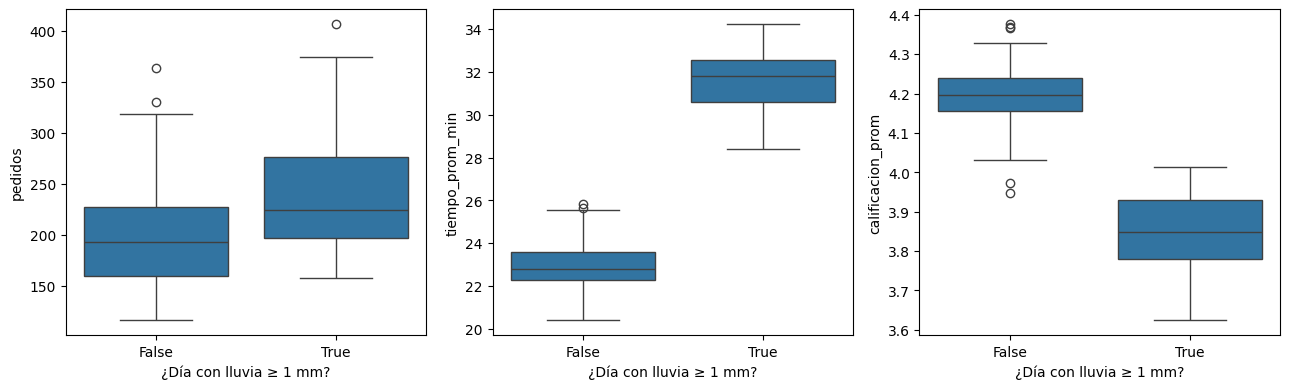

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, col in zip(ax, ["pedidos", "tiempo_prom_min", "calificacion_prom"]):
    sns.boxplot(data=d, x="dia_lluvioso", y=col, ax=a)
    a.set_xlabel("¿Día con lluvia ≥ 1 mm?")
plt.tight_layout(); plt.show()

In [25]:
d["llu"] = d.dia_lluvioso.astype(int)
d["fer"] = d.feriado.astype(int)
d["trend"] = range(len(d))
m = smf.ols("pedidos ~ llu + C(dia_semana) + trend + fer", data=d).fit(cov_type="HC1")
print(m.summary().tables[1])

                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            167.2293      3.501     47.768      0.000     160.368     174.091
C(dia_semana)[T.1]   -48.1041      3.459    -13.907      0.000     -54.884     -41.324
C(dia_semana)[T.2]   -51.9248      3.506    -14.810      0.000     -58.796     -45.053
C(dia_semana)[T.3]   -10.4598      4.922     -2.125      0.034     -20.106      -0.814
C(dia_semana)[T.4]   -24.9732      3.821     -6.536      0.000     -32.462     -17.485
C(dia_semana)[T.5]    31.8896      3.629      8.787      0.000      24.777      39.003
C(dia_semana)[T.6]    52.5293      4.227     12.428      0.000      44.245      60.813
llu                   57.3166      3.159     18.145      0.000      51.126      63.508
trend                  0.1719      0.012     14.632      0.000       0.149       0.195
fer                   62.7931     12.697   

In [26]:
did = con.sql("""
SELECT es_miercoles, post_promo, COUNT(*) AS dias,
       ROUND(AVG(pedidos), 1)   AS pedidos_prom,
       ROUND(AVG(gmv), 0)       AS gmv_prom,
       ROUND(AVG(envios_bs), 0) AS envios_prom
FROM oro_diario
GROUP BY 1, 2 ORDER BY 1, 2
""").df()
print(did)

t = did.pivot(index="es_miercoles", columns="post_promo", values="pedidos_prom")
cambio = t[True] - t[False]
print("Cambio miércoles:", cambio[True], "| Cambio otros días:", cambio[False])
print("Diferencia en diferencias (pedidos):", cambio[True] - cambio[False])

   es_miercoles  post_promo  dias  pedidos_prom  gmv_prom  envios_prom
0         False       False   156         198.3   11765.0       2055.0
1         False        True   156         214.2   12712.0       2242.0
2          True       False    26         162.6    9700.0       1689.0
3          True        True    27         244.8   12689.0          0.0
Cambio miércoles: 82.20000000000002 | Cambio otros días: 15.899999999999977
Diferencia en diferencias (pedidos): 66.30000000000004


In [27]:
d["mie"] = d.es_miercoles.astype(int)
d["post"] = d.post_promo.astype(int)
m = smf.ols("pedidos ~ mie * post", data=d).fit(cov_type="HC1")
print(m.summary().tables[1])   # la fila "mie:post" es el efecto de la promo

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    198.3269      3.563     55.663      0.000     191.344     205.310
mie          -35.7115      5.997     -5.955      0.000     -47.466     -23.957
post          15.8718      5.446      2.915      0.004       5.198      26.545
mie:post      66.3276     11.174      5.936      0.000      44.427      88.228


In [28]:
ing = con.sql("""
SELECT fecha,
       SUM(monto_bs * rest_comision_pct / 100.0) AS comision_bs,
       SUM(costo_envio_bs)                       AS envio_bs
FROM oro_pedidos_enriquecido
WHERE estado = 'entregado'
GROUP BY fecha
""").df()
ing["fecha"] = pd.to_datetime(ing["fecha"])
d2 = d.merge(ing, on="fecha", how="left").fillna({"comision_bs": 0, "envio_bs": 0})
d2["ingreso_bs"] = d2.comision_bs + d2.envio_bs

m2 = smf.ols("ingreso_bs ~ mie * post", data=d2).fit(cov_type="HC1")
print(m2.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   4215.2770     74.740     56.399      0.000    4068.788    4361.766
mie         -747.0425    128.878     -5.797      0.000    -999.638    -494.447
post         369.8760    114.754      3.223      0.001     144.962     594.791
mie:post   -1515.9952    172.449     -8.791      0.000   -1853.989   -1178.002


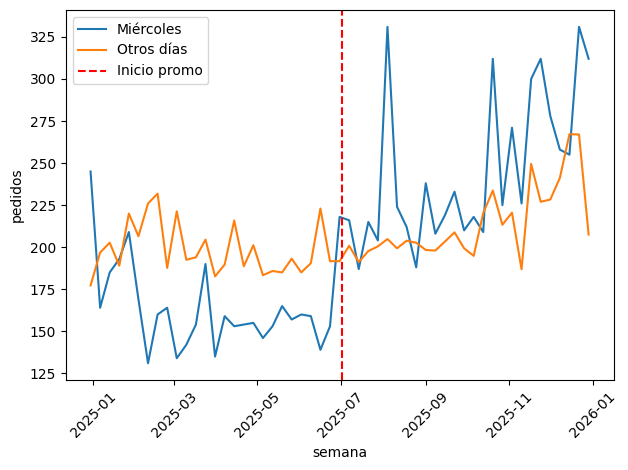

In [29]:
d2["semana"] = d2.fecha.dt.to_period("W").dt.start_time
d2["grupo"] = d2.mie.map({1: "Miércoles", 0: "Otros días"})
sem = d2.groupby(["semana", "grupo"])["pedidos"].mean().reset_index()
sns.lineplot(data=sem, x="semana", y="pedidos", hue="grupo")
plt.axvline(pd.Timestamp("2025-07-02"), color="red", ls="--", label="Inicio promo")
plt.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()